<a href="https://colab.research.google.com/github/Alexandra719/PMP-2026/blob/main/PMP_Tema1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Ex. 1. Scrieţi un program în Python care să preia ca input un fişier .csv cu o listă oarecare şi să aibă ca output un număr
predeterminat de elemente din acea listă, fără repetiţie. Aplicaţi pe lista studenţilor din grupa dumneavoastră care nu
au prezentat încă o temă.

Notă: Pentru generarea unui eşantion aleator se poate apela funcţia sample din modulul random sau funcţia ran-
dom.choice cu argumentul replace=False din librăria Numpy.

In [2]:
import csv
import random

def studenti(name_fisier, number):
  lista = []
  fisier = open(name_fisier, mode="r", encoding="utf-8")
  tabel = csv.DictReader(fisier)

  for rand in tabel:
      if rand["tema_prezentata"].strip().lower() == "nu":
         lista.append(rand["nume"])
  fisier.close()

  if len(lista) < number:
     print(f"Atenție! Sunt doar {len(lista)} studenti fără temă.")
     number = len(lista)

  esantion = random.sample(lista,number)

  return esantion

rezultat = studenti("studenti.csv", 2)

print("Studenții extrași sunt:", rezultat)


Studenții extrași sunt: ['Casandra', 'Bianca']


Ex. 2. Doi prieteni joacă următorul joc, după următoarele reguli:

Pasul 1. Primul jucător aruncă cu o monedă.

● Dacă pică stemă, cel de-al doilea trebuie să arunce cu zarul şi să-i dea primului o sumă egală z - 3, unde z este rezultatul aruncării cu zarul (a da o sumă negativă este echivalent cu a lua opusul acelei sume). Jocul se încheie aici.

● Dacă pică ban, atunci primul jucător trebuie să-i dea celui de-al doilea 0.5.
Pasul n. În caz că jocul nu s-a încheiat, se reia pasul 1.

Astfel, jocul se opreşte la pasul corespunzător obţinerii stemei de către primul jucător.

a) Ce fel de distribuţie urmează N, numărul de paşi ai jocului?

b) Simulaţi în Python un astfel de joc. Variabilele care ne interesează sunt N şi suma totală S pe care cel de-al
doilea jucător trebuie să i-o dea primului.

c) Prin simularea unui număr mare de astfel de jocuri, determinaţi cu aproximaţie media lui S şi reprezentaţi grafic
(printr-o histogramă) distribuţia acesteia.

d) Ce se întâmplă dacă moneda este măsluită? Încercaţi să refaceţi pct. c) cu o probabilitate de apariţie a stemei
p = 0.3, respectiv p = 0.7.

a) Distribuție geometrică : Jocul constă în repetiții independente ale aceluiași experiment până la apariția primului succes.

Numărul de pași ai jocului (N): 1
Suma totală câștigată/pierdută (S): 2 dolari
După 10.000 de simulări cu o monedă corectă:
Valoarea medie a sumei S este aproximativ: 0.99 dolari


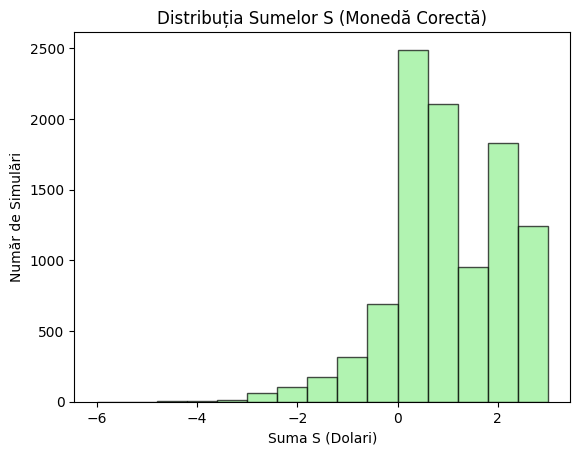

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

p_stema = 0.5
nr_simulari = 10000

toate_sumele = []

for i in range(nr_simulari):
  suma_joc = 0
  pasi_joc = 0
  moneda_stema = False

  while moneda_stema == False:
    pasi_joc = pasi_joc + 1
    aruncare = np.random.rand()

    if aruncare < p_stema:
      zar = np.random.randint(1,7)
      suma_joc = suma_joc + abs(zar - 3)
      moneda_stema = True
    else:
      suma_joc = suma_joc - 0.5

  toate_sumele.append(suma_joc)

  if i == 0:
    print(f"Numărul de pași ai jocului (N): {pasi_joc}")
    print(f"Suma totală câștigată/pierdută (S): {suma_joc} dolari")

media_sumelor = np.mean(toate_sumele)

print(f"După 10.000 de simulări cu o monedă corectă:")
print(f"Valoarea medie a sumei S este aproximativ: {media_sumelor:.2f} dolari")

plt.hist(toate_sumele, bins=15, alpha=0.7, color="lightgreen", edgecolor="black")

plt.title("Distribuția Sumelor S (Monedă Corectă)")
plt.xlabel("Suma S (Dolari)")
plt.ylabel("Număr de Simulări")


plt.show()


Pentru p = 0.3 (Stema pică mai greu): Media lui S este  0.34 dolari
Pentru p = 0.7 (Stema pică mai repede): Media lui S este  1.28 dolari



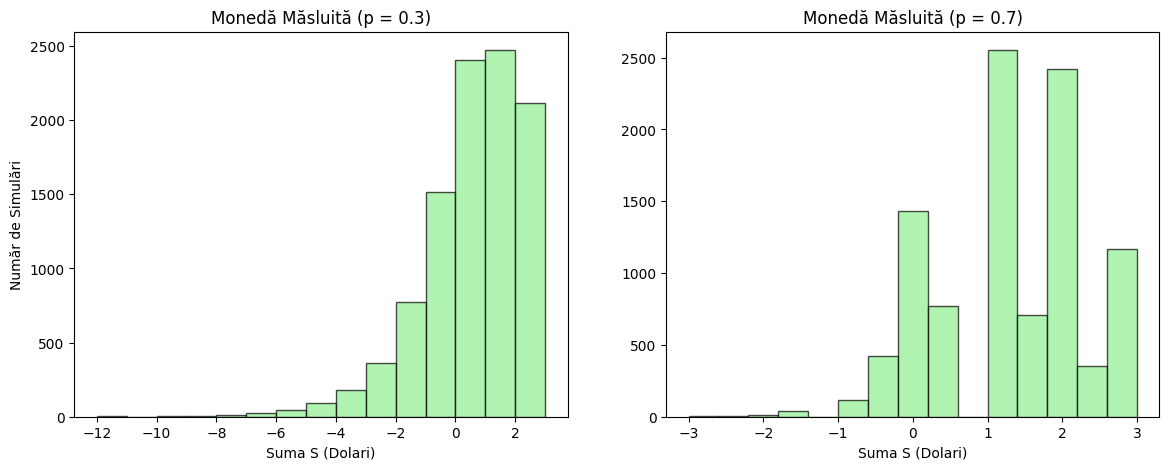

In [3]:
import matplotlib.pyplot as plt
import numpy as np

nr_simulari = 10000

p_stema_03 = 0.3
toate_sumele_03 = []

for i in range(nr_simulari):
    suma_joc = 0
    moneda_stema = False
    while moneda_stema == False:
        aruncare = np.random.rand()
        if aruncare < p_stema_03:
            zar = np.random.randint(1, 7)
            suma_joc = suma_joc + abs(zar - 3)
            moneda_stema = True
        else:
            suma_joc = suma_joc - 0.5
    toate_sumele_03.append(suma_joc)

media_03 = np.mean(toate_sumele_03)

p_stema_07 = 0.7
toate_sumele_07 = []

for i in range(nr_simulari):
    suma_joc = 0
    moneda_stema = False
    while moneda_stema == False:
        aruncare = np.random.rand()
        if aruncare < p_stema_07:
            zar = np.random.randint(1, 7)
            suma_joc = suma_joc + abs(zar - 3)
            moneda_stema = True
        else:
            suma_joc = suma_joc - 0.5
    toate_sumele_07.append(suma_joc)

media_07 = np.mean(toate_sumele_07)

print(f"Pentru p = 0.3 (Stema pică mai greu): Media lui S este  {media_03:.2f} dolari")
print(f"Pentru p = 0.7 (Stema pică mai repede): Media lui S este  {media_07:.2f} dolari\n")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.hist(toate_sumele_03, bins=15, alpha=0.7, color="lightgreen", edgecolor="black")
ax1.set_title("Monedă Măsluită (p = 0.3)")
ax1.set_xlabel("Suma S (Dolari)")
ax1.set_ylabel("Număr de Simulări")



ax2.hist(toate_sumele_07, bins=15, alpha=0.7, color="lightgreen", edgecolor="black")
ax2.set_title("Monedă Măsluită (p = 0.7)")
ax2.set_xlabel("Suma S (Dolari)")



plt.show()


Ex. 3. Într-o frizerie, trei frizeri îşi tund clienţii cu următoarele viteze medii: primul cu 3 clienţi pe oră, al doilea cu 6 pe
oră iar al treilea cu 4 pe oră. Astfel, timpul de servire al unui client este modelat de distribuţii exponenţiale cu parametrii
λ1 = 3 h−1
, λ2 = 6 h−1
, respectiv λ3 = 4 h−1
, iar probabilităţile de preluare a unui client de către un anumit frizer sunt
3/13, 6/13, respectiv 4/13 (de ce?). Fie X timpul de servire pentru un client.

Generaţi 10000 de valori pentru X, şi în felul acesta estimaţi media şi deviaţia standard a lui X. Realizaţi un grafic
aproximativ al densităţii distribuţiei lui X.

Notă: Distribuţia Exp(λ) se poate apela prin random.exponential(scale=1/λ) în Numpy, sau cu stats.expon(scale=1/λ)
în Scipy. Având în vedere că X are o distribuţie continuă, densitatea aproximativă acesteia se poate vizualiza folosind
funcţia plot_kde din librăria Arviz.

Probabilitățiile sunt 3/13, 6/13, 4/13 deoarece probabilitățile sunt proporționale cu viteza de lucru a fiecărui frizer. Cu cât un frizer termină mai repede un client, cu atât el devine liber mai des și are o șansă mai mare să preia urmatorul client care intră pe ușă. Rata totală de servire a frizeriei este suma tuturor vitezelor λ totala = 3 + 6 + 4 = 13 clienți/oră.

Media estimată a lui X: 0.2301 ore
Deviația standard estimată a lui X: 0.2483 ore



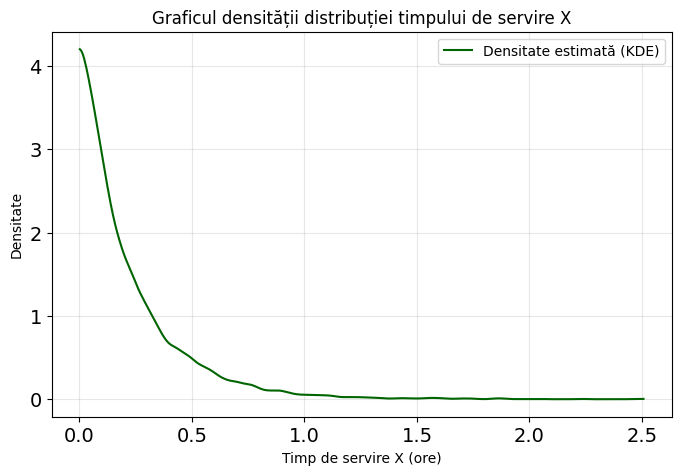

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np

nr_simulari = 10000
valori_X = []
lambda1, lambda2, lambda3 = 3, 6, 4
probabilitati = [3 / 13, 6 / 13, 4 / 13]

for i in range(nr_simulari):
    frizer_ales = np.random.choice([1, 2, 3], p=probabilitati)

    if frizer_ales == 1:
        timp = np.random.exponential(scale=1 / lambda1)
    elif frizer_ales == 2:
        timp = np.random.exponential(scale=1 / lambda2)
    else:
        timp = np.random.exponential(scale=1 / lambda3)

    valori_X.append(timp)

valori_X = np.array(valori_X)

media_estimata = np.mean(valori_X)
deviatia_standard_estimata = np.std(valori_X)

print(f"Media estimată a lui X: {media_estimata:.4f} ore")
print(f"Deviația standard estimată a lui X: {deviatia_standard_estimata:.4f} ore\n")

plt.figure(figsize=(8, 5))
az.plot_kde(valori_X, label="Densitate estimată (KDE)", plot_kwargs={"color": "darkgreen"},)
plt.title("Graficul densității distribuției timpului de servire X")
plt.xlabel("Timp de servire X (ore)")
plt.ylabel("Densitate")
plt.grid(True, alpha=0.3)
plt.show()